# PriceWise | Final Validation of the Product Selection (US and Canada)

This notebook runs the **Final Validation Rule** on the team's current selection method (`Top30_NEW.ipynb`):

| Rule | What this notebook checks |
|---|---|
| 1. Covers the major product types, families, price levels and activity levels | Type, major-family (≥5% of revenue), price-tier, revenue-tier and activity-tier coverage |
| 2. Has distributions reasonably similar to the eligible population | 16 features: price level and behaviour (ASP, dispersion, outliers, margin, customer concentration) and size / activity (revenue, units, transactions, active weeks, active rate, history span) |
| 3. Remains stable under small changes to the selection rules | One-at-a-time rule changes (20 for the US, 13 for Canada), per-product selection frequency, and a "how strict can we go" path |
| 4. Produces acceptable model performance on eligible products outside the selection | A weekly price baseline trained on the selected products, scored on every other active product, overall and by segment; plus product-holdout cross-validation |

**What it adds to `Product_Selection_Thorough_Validation.ipynb`:** that notebook worked only from saved output tables, so it could check US type/family shares and the final usable-week minimums. This one works from the raw transactions, so it can also check price, revenue and activity distributions, vary the transaction gates themselves, cover Canada, and test model performance outside the selection.

**Eligible population.** The comparison population is every Enterprise hardware product group (Notebook, Workstations, Desktop, Visuals) with at least one sale in the recent 6-month window (Mar–Aug 2026), because that is the market the model has to price. The 76 US "initial candidates" are reported alongside where useful.

**Data:** the team's shared `valid_US.csv` and `valid_CA.csv`.

**Run:** set `DATA_FILES` below, then run all cells (about 3 minutes; later runs are faster because the core rows are cached).

## 0 | Setup

In [1]:
# %pip install pandas numpy scipy matplotlib pyarrow
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_FILES = {
    # The team's shared files (all segments); the loader keeps Enterprise only.
    "US": Path(os.environ.get("PW_US", Path.home() / "Downloads" / "valid_US.csv")),
    "CA": Path(os.environ.get("PW_CA", Path.home() / "Downloads" / "valid_CA.csv")),
}
# Optional: the exploratory "proposed" lists, compared in section 6 if present.
PROPOSED_LISTS = {
    "US": Path(os.environ.get("PW_LISTS", Path.home() / "Downloads")) / "US_selected_product_newlist.csv",
    "CA": Path(os.environ.get("PW_LISTS", Path.home() / "Downloads")) / "CA_selected_product_newlist.csv",
}
OUT = Path.cwd() / "validation_outputs"
OUT.mkdir(exist_ok=True)

# Acceptance guides used in the scorecard (team to confirm)
MEDIAN_DIFF_FLAG = 0.20      # rule 2: price-feature medians within 20% of the population
MIN_RETENTION = 0.80         # rule 3: small rule changes keep >= 80% of the selection
MAX_OUTSIDE_RATIO = 1.25     # rule 4: error outside the selection <= 1.25x error inside
MAX_SEGMENT_RATIO = 1.50     # rule 4: no segment (>= 100 test weeks) worse than 1.5x the selected error

SEL_C, POP_C = "#2a78d6", "#eb6834"   # selected / population
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2, "font.size": 9})
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
for c, p in DATA_FILES.items():
    print(c, p.exists(), p)

US True /home/claude/newdata/valid_US/valid_US.csv
CA True /home/claude/newdata/valid_CA_csv/valid_CA.csv


### Helper functions
Selection rule, product features, coverage, distributions, stability scenarios and the price baseline. Everything else in the notebook calls these.

In [2]:
from dataclasses import dataclass, replace, asdict
import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy import sparse

KEYS = ["product_name", "product_family", "product_type"]
TYPES = ["Notebook", "Workstations", "Desktop", "Visuals"]


# --------------------------------------------------------------------------- rule
@dataclass(frozen=True)
class Rule:
    recent_tx: int            # recent 6 months: transactions must be > this
    recent_active_months: int # ... with at least this many active months
    hist_tx: int              # each 6-month historical period: transactions > this
    min_hist_periods: int     # ... in at least this many of the 3 periods
    weekly: bool              # apply the usable-week screen?
    past30_min: int = 5       # usable week: >= this many tx in the prior 30 days
    future7_min: int = 2      # ... and >= this many tx in the next 7 days
    min_recent_weeks: int = 9
    min_hist_weeks: int = 7


BASE_RULE = {
    "US": Rule(100, 3, 100, 2, weekly=True),
    "CA": Rule(50, 3, 50, 2, weekly=False),
}


# --------------------------------------------------------------------------- windows
def windows(max_date):
    cutoff_month = max_date.to_period("M") - 1
    end_excl = (cutoff_month + 1).to_timestamp()
    recent_start = end_excl - pd.DateOffset(months=6)
    history_start = recent_start - pd.DateOffset(months=18)
    return dict(cutoff_month=cutoff_month, end_excl=end_excl,
                cutoff_date=end_excl - pd.Timedelta(days=1),
                recent_start=recent_start, history_start=history_start)


# --------------------------------------------------------------------------- per-group stats
def group_stats(tx, W):
    """Everything the rule and the validation need, one row per product group.
    Population = groups with at least one transaction in the recent 6 months."""
    d = tx[tx.pricing_date < W["end_excl"]].copy()
    d["pid"] = d.groupby(KEYS, observed=True).ngroup()
    recent = d[d.pricing_date >= W["recent_start"]]
    pop_ids = np.sort(recent.pid.unique())
    d = d[d.pid.isin(pop_ids)]
    recent = d[d.pricing_date >= W["recent_start"]]
    hist = d[(d.pricing_date >= W["history_start"]) & (d.pricing_date < W["recent_start"])]

    g = d.groupby("pid")
    out = d.drop_duplicates("pid").set_index("pid")[KEYS].copy()
    out["first_sale"] = g.pricing_date.min()
    rg = recent.groupby("pid")
    out["recent_tx"] = rg.size()
    out["recent_active_months"] = rg.pricing_date.apply(lambda s: s.dt.to_period("M").nunique())
    per = ((hist.pricing_date.dt.year - W["history_start"].year) * 12
           + hist.pricing_date.dt.month - W["history_start"].month) // 6
    hp = hist.assign(per=per).groupby(["pid", "per"]).size().unstack(fill_value=0)
    for i in range(3):
        out[f"hist_tx_p{i}"] = hp.get(i, pd.Series(dtype=float)).reindex(out.index).fillna(0)
    out["hist_tx_total"] = out[[f"hist_tx_p{i}" for i in range(3)]].sum(axis=1)

    # ---------------- validation features (computed at the cutoff)
    last90 = d[d.pricing_date >= W["end_excl"] - pd.Timedelta(days=90)]
    l90 = last90.groupby("pid")
    out["revenue_90d"] = l90.revenue.sum()
    out["units_90d"] = l90.order_units.sum()
    out["tx_90d"] = l90.size()
    out["active_weeks_90d"] = l90.pricing_date.apply(lambda s: s.dt.to_period("W").nunique())
    out["asp90"] = out.revenue_90d / out.units_90d
    out["revenue_6m"] = rg.revenue.sum()
    out["units_6m"] = rg.order_units.sum()
    out["asp_6m"] = out.revenue_6m / out.units_6m
    up = recent.revenue / recent.order_units
    out["price_cv_6m"] = up.groupby(recent.pid).std() / up.groupby(recent.pid).mean()
    out["margin_pct_6m"] = rg.margin.sum() / out.revenue_6m
    out["customers_6m"] = rg.customer_id.nunique()
    cs = recent.groupby(["pid", "customer_id"]).revenue.sum()
    out["top_customer_share_6m"] = cs.groupby(level=0).max() / cs.groupby(level=0).sum()
    out["history_span_days"] = (W["cutoff_date"] - out.first_sale).dt.days
    wk = d.pricing_date.dt.to_period("W")
    active_w = wk.groupby(d.pid).nunique()
    weeks_since_first = ((W["cutoff_date"] - out.first_sale).dt.days // 7 + 1)
    out["active_rate"] = (active_w / weeks_since_first).clip(upper=1)
    # price-outlier rate over the last 12 months (1.5 IQR on transaction ASP)
    y12 = d[d.pricing_date >= W["end_excl"] - pd.DateOffset(months=12)]
    a = y12.revenue / y12.order_units
    q1 = a.groupby(y12.pid).transform(lambda s: s.quantile(.25))
    q3 = a.groupby(y12.pid).transform(lambda s: s.quantile(.75))
    iqr = q3 - q1
    out["price_outlier_rate"] = ((a < q1 - 1.5 * iqr) | (a > q3 + 1.5 * iqr)).groupby(y12.pid).mean()
    out = out.fillna({"revenue_90d": 0, "units_90d": 0, "tx_90d": 0, "active_weeks_90d": 0})
    return out, d


# --------------------------------------------------------------------------- weekly support arrays
def weekly_support(d, W, pids):
    """past30 / past90 / future7 transaction counts at each 7-day checkpoint, per group
    (replicates Top30_NEW cell 11 exactly), plus ASP features for the model test."""
    dates = pd.date_range(W["history_start"], W["cutoff_date"] - pd.Timedelta(days=7), freq="7D")
    rows = []
    sub = d[d.pid.isin(pids)]
    daily = sub.groupby(["pid", sub.pricing_date.dt.normalize()]).agg(
        tx=("revenue", "size"), rev=("revenue", "sum"), units=("order_units", "sum"))
    for pid, g in daily.groupby(level=0):
        g = g.droplevel(0)
        idx = pd.date_range(g.index.min(), W["cutoff_date"], freq="D")
        g = g.reindex(idx, fill_value=0)
        t = g.tx
        past30 = t.shift(1).rolling(30, min_periods=30).sum()
        past90 = t.shift(1).rolling(90, min_periods=90).sum()
        fut = lambda s: s.shift(-1).iloc[::-1].rolling(7, min_periods=7).sum().iloc[::-1]
        f7 = fut(t)
        f = pd.DataFrame({"past30": past30, "past90": past90, "future7": f7,
                          "fut_rev": fut(g.rev), "fut_units": fut(g.units)})
        for k in (7, 30, 90, 180):
            r = g.rev.shift(1).rolling(k, min_periods=1).sum()
            u = g.units.shift(1).rolling(k, min_periods=1).sum()
            f[f"asp{k}"] = (r / u.replace(0, np.nan))
        f = f.reindex(dates)
        f["pid"] = pid
        rows.append(f)
    ws = pd.concat(rows).rename_axis("checkpoint").reset_index()
    ws["is_recent"] = ws.checkpoint >= W["recent_start"]
    ws["is_hist"] = ws.checkpoint + pd.Timedelta(days=7) < W["recent_start"]
    return ws


def usable_weeks(ws, rule):
    v = (ws.past30.ge(rule.past30_min) & ws.past90.gt(0) & ws.future7.ge(rule.future7_min))
    rec = v[ws.is_recent].groupby(ws.pid[ws.is_recent]).sum()
    his = v[ws.is_hist].groupby(ws.pid[ws.is_hist]).sum()
    return rec, his


# --------------------------------------------------------------------------- apply the rule
def select(stats, ws, rule):
    hist_pass = sum((stats[f"hist_tx_p{i}"] > rule.hist_tx).astype(int) for i in range(3))
    cand = ((stats.recent_tx > rule.recent_tx) & (stats.recent_active_months >= rule.recent_active_months)
            & (hist_pass >= rule.min_hist_periods))
    if not rule.weekly:
        return cand, cand
    rec, his = usable_weeks(ws, rule)
    rec = rec.reindex(stats.index).fillna(0)
    his = his.reindex(stats.index).fillna(0)
    sel = cand & (rec >= rule.min_recent_weeks) & (his >= rule.min_hist_weeks)
    return cand, sel


# --------------------------------------------------------------------------- tiers & coverage
def add_tiers(stats):
    s = stats.copy()
    s["price_tier"] = s.groupby("product_type").asp90.transform(
        lambda x: pd.qcut(x.rank(method="first"), 3, labels=["Low", "Medium", "High"]))
    s["price_tier"] = s.price_tier.astype("string").fillna("No sale in 90d")
    s["revenue_tier"] = pd.qcut(s.revenue_6m.rank(method="first"), 3, labels=["Low", "Medium", "High"]).astype("string")
    s["activity_tier"] = pd.qcut(s.recent_tx.rank(method="first"), 3, labels=["Low", "Medium", "High"]).astype("string")
    return s


def major_families(stats, share=0.05):
    r = stats.groupby("product_family").revenue_6m.sum()
    r = r / r.sum()
    return sorted(r[r >= share].index)


def coverage_table(stats, sel_mask):
    rows = []
    majors = major_families(stats)
    for dim in ["product_type", "product_family", "price_tier", "revenue_tier", "activity_tier"]:
        pop = stats[dim].value_counts()
        selc = stats.loc[sel_mask, dim].value_counts().reindex(pop.index).fillna(0).astype(int)
        rev_pop = stats.groupby(dim).revenue_6m.sum()
        rev_sel = stats[sel_mask].groupby(dim).revenue_6m.sum().reindex(rev_pop.index).fillna(0)
        for k in pop.index:
            rows.append(dict(dimension=dim, level=k, population_products=int(pop[k]), selected_products=int(selc[k]),
                             population_product_share=pop[k] / pop.sum(),
                             selected_product_share=selc[k] / max(selc.sum(), 1),
                             population_revenue_share=rev_pop[k] / rev_pop.sum(),
                             selected_revenue_share=rev_sel[k] / max(rev_sel.sum(), 1),
                             revenue_covered=rev_sel[k] / rev_pop[k] if rev_pop[k] > 0 else np.nan,
                             major_family=(k in majors) if dim == "product_family" else None))
    return pd.DataFrame(rows)


def coverage_scores(stats, sel_mask):
    majors = major_families(stats)
    sel = stats[sel_mask]
    return dict(
        types_covered=f"{sel.product_type.nunique()}/{stats.product_type.nunique()}",
        major_families=", ".join(m.replace("Product Family ", "") for m in majors),
        major_family_coverage=np.mean([m in set(sel.product_family) for m in majors]),
        price_tiers=sorted(set(sel.price_tier) - {"No sale in 90d"}),
        revenue_tiers=sorted(set(sel.revenue_tier)),
        activity_tiers=sorted(set(sel.activity_tier)),
        selected=int(sel_mask.sum()), population=len(stats),
        revenue_share_6m=sel.revenue_6m.sum() / stats.revenue_6m.sum(),
    )


# --------------------------------------------------------------------------- distributions
FEATURES = {
    # price level and behaviour (should look like the population)
    "asp90": "ASP, last 90 days ($/unit)",
    "asp_6m": "ASP, last 6 months ($/unit)",
    "price_cv_6m": "Price dispersion (CV of transaction ASP, 6m)",
    "price_outlier_rate": "Price-outlier rate (1.5 IQR, 12m)",
    "margin_pct_6m": "Margin %, 6m",
    "top_customer_share_6m": "Top-customer revenue share, 6m",
    # size and activity (selected on, so expected to be higher)
    "revenue_90d": "Revenue, last 90 days ($)",
    "revenue_6m": "Revenue, last 6 months ($)",
    "units_6m": "Units, last 6 months",
    "recent_tx": "Transactions, last 6 months",
    "tx_90d": "Transactions, last 90 days",
    "active_weeks_90d": "Active weeks, last 90 days",
    "recent_active_months": "Active months, last 6 months",
    "active_rate": "Active rate (weeks with a sale / weeks since first sale)",
    "customers_6m": "Distinct customers, 6m",
    "history_span_days": "History span (days since first sale)",
}
PRICE_FEATURES = ["asp90", "asp_6m", "price_cv_6m", "price_outlier_rate", "margin_pct_6m", "top_customer_share_6m"]


def distribution_table(stats, sel_mask, comparator_mask, flag_pct=0.20):
    from scipy.stats import ks_2samp
    rows = []
    for f, label in FEATURES.items():
        a = stats.loc[sel_mask, f].dropna()
        b = stats.loc[comparator_mask, f].dropna()
        med_a, med_b = a.median(), b.median()
        diff = (med_a - med_b) / abs(med_b) if med_b not in (0, np.nan) and med_b != 0 else np.nan
        rows.append(dict(feature=f, label=label, group="price" if f in PRICE_FEATURES else "size/activity",
                         sel_p25=a.quantile(.25), sel_median=med_a, sel_p75=a.quantile(.75),
                         pop_p25=b.quantile(.25), pop_median=med_b, pop_p75=b.quantile(.75),
                         median_diff=diff, flag_gt_20pct=bool(abs(diff) > flag_pct) if pd.notna(diff) else None,
                         ks_stat=ks_2samp(a, b).statistic if len(a) > 1 and len(b) > 1 else np.nan))
    return pd.DataFrame(rows)


def type_adjusted_price(stats, sel_mask):
    """ASP compared within product type (a laptop is not a monitor)."""
    rows = []
    for t, g in stats.groupby("product_type"):
        s = g.loc[sel_mask.reindex(g.index), "asp90"].dropna()
        p = g.asp90.dropna()
        if len(s) == 0:
            rows.append(dict(product_type=t, selected=0, sel_median_asp90=np.nan, pop_median_asp90=p.median(),
                             median_diff=np.nan, sel_percentile_of_median=np.nan))
            continue
        rows.append(dict(product_type=t, selected=len(s), sel_median_asp90=s.median(), pop_median_asp90=p.median(),
                         median_diff=s.median() / p.median() - 1,
                         sel_percentile_of_median=(p < s.median()).mean()))
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- stability
def scenario_grid(country):
    b = BASE_RULE[country]
    tx_vals = [75, 90, 110, 125] if country == "US" else [35, 45, 55, 65]
    S = [("Base", b)]   # scenarios after "Base": small = within about +/-25% of a threshold
    for v in tx_vals:
        S.append((f"recent tx > {v}", replace(b, recent_tx=v)))
    for v in tx_vals:
        S.append((f"history tx > {v}", replace(b, hist_tx=v)))
    for v in (2, 4):
        S.append((f"active months >= {v}", replace(b, recent_active_months=v)))
    for v in (1, 3):
        S.append((f"history periods >= {v} [large]", replace(b, min_hist_periods=v)))
    if b.weekly:
        for v in (8, 10):
            S.append((f"recent usable weeks >= {v}", replace(b, min_recent_weeks=v)))
        for v in (6, 8):
            S.append((f"history usable weeks >= {v}", replace(b, min_hist_weeks=v)))
        for v in (4, 6):
            S.append((f"past-30-day tx >= {v}", replace(b, past30_min=v)))
        for v in (1, 3):
            S.append((f"next-7-day tx >= {v}", replace(b, future7_min=v)))
    else:
        S.append(("+ US-style weekly screen [large]", replace(b, weekly=True)))
    return S


def strictness_path(country):
    """Tighten every gate together. k multiplies the transaction gates; the other
    gates step up with k so that 'strict' means strict on every dimension."""
    b = BASE_RULE[country]
    out = []
    for k in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]:
        step = 0 if k <= 1 else (1 if k <= 1.5 else 2 if k <= 2.5 else 3)
        r = replace(b, recent_tx=int(round(b.recent_tx * k)), hist_tx=int(round(b.hist_tx * k)),
                    recent_active_months=min(6, b.recent_active_months + step),
                    min_hist_periods=b.min_hist_periods,   # kept at 2: requiring all 3 periods = 24 months of history, which no current laptop has
                    min_recent_weeks=int(round(b.min_recent_weeks * max(k, 1) ** 0.5)) if b.weekly else b.min_recent_weeks,
                    min_hist_weeks=int(round(b.min_hist_weeks * max(k, 1) ** 0.5)) if b.weekly else b.min_hist_weeks)
        out.append((k, r))
    return out


# --------------------------------------------------------------------------- model test
COMPONENTS = ["asp7", "asp30", "asp90", "asp180"]


def fit_relative_lad(X, y, scale):
    """Convex weights minimising sum |y - Xw| / scale (= sum of absolute % errors)."""
    Xs, ys = X / scale[:, None], y / scale
    n, k = Xs.shape
    c = np.r_[np.zeros(k), np.ones(2 * n)]
    A = sparse.vstack([sparse.hstack([sparse.csr_matrix(Xs), sparse.eye(n), -sparse.eye(n)]),
                       sparse.csr_matrix(np.r_[np.ones(k), np.zeros(2 * n)][None, :])]).tocsr()
    res = linprog(c, A_eq=A, b_eq=np.r_[ys, 1.0], bounds=[(0, None)] * (k + 2 * n), method="highs")
    w = res.x[:k]
    w[w < 1e-6] = 0
    return w / w.sum()


def model_frame(ws):
    """Evaluable weekly samples: a past ASP exists (>=1 sale in prior 30 days) and the
    next-7-day ASP is observed (>=1 sale). Missing short windows fall back to longer ones."""
    m = ws.copy()
    m["target"] = m.fut_rev / m.fut_units.replace(0, np.nan)
    m = m[m.asp30.notna() & m.target.notna() & (m.target > 0)].copy()
    m["asp90"] = m.asp90.fillna(m.asp30)
    m["asp180"] = m.asp180.fillna(m.asp90)
    m["asp7"] = m.asp7.fillna(m.asp30)
    return m


def err_metrics(y, f):
    ape = np.abs(f - y) / y
    return dict(samples=len(y), MAPE=ape.mean(), median_APE=np.median(ape),
                price_WAPE=np.abs(f - y).sum() / y.sum(), bias=(f - y).sum() / y.sum(),
                within_5pct=(ape <= .05).mean())


# --------------------------------------------------------------------------- product holdout
def product_holdout(m, train_pids, k=5, seed=0):
    """Group k-fold over products: fit on the historical weeks of k-1 folds, score the
    recent weeks of the held-out fold. Every product is held out exactly once."""
    rng = np.random.default_rng(seed)
    pids = np.array(sorted(train_pids))
    rng.shuffle(pids)
    folds = np.array_split(pids, k)
    out = []
    for i, f in enumerate(folds):
        tr = m[m.is_hist & m.pid.isin(set(pids) - set(f))]
        w = fit_relative_lad(tr[COMPONENTS].values, tr.target.values, tr.asp90.values)
        te = m[m.is_recent & m.pid.isin(f)].copy()
        te["forecast"] = te[COMPONENTS].values @ w
        te["fold"] = i
        out.append(te)
    return pd.concat(out)


def map_list(path, stats):
    """Match a product-list CSV (product_name, product_family, product_type) to groups."""
    lst = pd.read_csv(path, dtype="string")
    lst["product_type"] = lst.product_type.replace({"Workstation": "Workstations"})
    keys = set(lst[KEYS].drop_duplicates().itertuples(index=False, name=None))
    k = pd.Series(list(stats[KEYS].itertuples(index=False, name=None)), index=stats.index)
    return k.isin(keys), len(keys)

### Load Enterprise hardware transactions
Keeps the Enterprise segment only (the shared `valid_US.csv` / `valid_CA.csv` also hold Personal and Partner Channel), the four hardware types, and positive units and revenue. `pricing_date` = ship date, falling back to order date, exactly as in `Top30_NEW.ipynb`. Duplicate rows are kept, as in the selection notebook.

In [3]:
CORE_COLS = ["order_date", "ship_date", "customer_id", "product_id", "product_name", "product_family",
             "product_type", "order_units", "revenue", "cost", "margin", "segment"]

def load_core(country):
    src = DATA_FILES[country]
    cache = OUT / f"{country}_{src.stem}_core.parquet"   # one cache per source file
    if cache.exists():
        return pd.read_parquet(cache)
    parts = [ch[ch.segment.eq("Enterprise") & ch.product_type.isin(TYPES)
                & ch.order_units.gt(0) & ch.revenue.gt(0)]
             for ch in pd.read_csv(src, usecols=CORE_COLS, chunksize=500_000, low_memory=False)]
    d = pd.concat(parts, ignore_index=True).drop(columns="segment")
    d["order_date"] = pd.to_datetime(d.order_date, format="mixed")
    d["ship_date"] = pd.to_datetime(d.ship_date, format="mixed", errors="coerce")
    d["pricing_date"] = d.ship_date.fillna(d.order_date)
    for k in ["customer_id", "product_id", *KEYS]:
        d[k] = d[k].astype("string")
    d.to_parquet(cache, index=False)
    return d

tx = {c: load_core(c) for c in ["US", "CA"]}
W = windows(min(t.pricing_date.max() for t in tx.values()))
print(f"Recent window: {W['recent_start'].date()} to {W['cutoff_date'].date()} | "
      f"historical window: {W['history_start'].date()} to {(W['recent_start'] - pd.Timedelta(days=1)).date()}")
for c, t in tx.items():
    print(f"{c}: {len(t):,} Enterprise hardware rows")

Recent window: 2026-03-01 to 2026-08-31 | historical window: 2024-09-01 to 2026-02-28
US: 1,095,195 Enterprise hardware rows
CA: 204,853 Enterprise hardware rows


## 1 | Reproduce the current selection
The rule is rebuilt from the raw data. It must give the same 76 → 65 US product groups and 24 Canadian groups as `Top30_NEW.ipynb` before any validation means anything.

In [4]:
R = {}
for c in ["US", "CA"]:
    stats, d = group_stats(tx[c], W)
    stats = add_tiers(stats)
    ws = weekly_support(d, W, stats.index)
    cand, sel = select(stats, ws, BASE_RULE[c])
    R[c] = dict(stats=stats, ws=ws, cand=cand, sel=sel, model=model_frame(ws))
    print(f"{c}: {len(stats)} active product groups | {cand.sum()} pass the transaction gates | {sel.sum()} selected")

assert R["US"]["cand"].sum() == 76 and R["US"]["sel"].sum() == 65, "US selection does not match Top30_NEW"
assert R["CA"]["sel"].sum() == 24, "CA selection does not match Top30_NEW"
print("Matches Top30_NEW.ipynb (US 76 -> 65, CA 24).")

US: 530 active product groups | 76 pass the transaction gates | 65 selected


CA: 453 active product groups | 24 pass the transaction gates | 24 selected
Matches Top30_NEW.ipynb (US 76 -> 65, CA 24).


## 2 | Rule 1 — Coverage of types, families, price levels and activity levels

A **major family** contributes at least 5% of the population's recent 6-month revenue. Price tiers are ASP90 terciles **within each product type** (a cheap laptop is compared with laptops, not monitors). Revenue and activity tiers are terciles of 6-month revenue and transactions across the population.

In [5]:
cov_rows = []
for c in ["US", "CA"]:
    s = coverage_scores(R[c]["stats"], R[c]["sel"])
    cov_rows.append({"country": c, **s})
cov_summary = pd.DataFrame(cov_rows).set_index("country")
display(cov_summary.style.format({"major_family_coverage": "{:.0%}", "revenue_share_6m": "{:.1%}"}))

for c in ["US", "CA"]:
    t = coverage_table(R[c]["stats"], R[c]["sel"])
    t.to_csv(OUT / f"{c}_coverage_table.csv", index=False)
    display(Markdown(f"**{c} — population vs selected, by product count and by revenue**"))
    display(t.drop(columns="major_family").style.format({k: "{:.1%}" for k in
            ["population_product_share", "selected_product_share", "population_revenue_share",
             "selected_revenue_share", "revenue_covered"]}).hide(axis="index"))

,types_covered,major_families,major_family_coverage,price_tiers,revenue_tiers,activity_tiers,selected,population,revenue_share_6m
country,,,,,,,,,
US,4/4,"Frame Road, Knight Thrive, Solar Peak, Titan Onset",100%,"['High', 'Low', 'Medium']","['High', 'Low', 'Medium']","['High', 'Medium']",65,530,35.4%
CA,4/4,"Frame Road, Knight Thrive, Solar Peak, Titan Onset",100%,"['High', 'Low', 'Medium']","['High', 'Low', 'Medium']",['High'],24,453,19.1%


**US — population vs selected, by product count and by revenue**

dimension,level,population_products,selected_products,population_product_share,selected_product_share,population_revenue_share,selected_revenue_share,revenue_covered
product_type,Notebook,239,35,45.1%,53.8%,59.0%,71.1%,42.6%
product_type,Workstations,126,14,23.8%,21.5%,30.6%,24.3%,28.2%
product_type,Desktop,119,10,22.5%,15.4%,8.4%,3.9%,16.3%
product_type,Visuals,46,6,8.7%,9.2%,2.1%,0.7%,12.3%
product_family,Product Family Solar Peak,132,14,25.0%,21.5%,31.4%,24.3%,27.5%
product_family,Product Family Knight Thrive,128,9,24.2%,13.8%,20.5%,16.1%,27.8%
product_family,Product Family Titan Onset,109,10,20.6%,15.4%,8.4%,3.9%,16.4%
product_family,Product Family Frame Road,103,26,19.5%,40.0%,37.7%,55.0%,51.6%
product_family,Product Family Quest Lunar,46,6,8.7%,9.2%,2.1%,0.7%,12.3%
product_family,Product Family Stream Juliet,9,0,1.7%,0.0%,0.0%,0.0%,0.0%


**CA — population vs selected, by product count and by revenue**

dimension,level,population_products,selected_products,population_product_share,selected_product_share,population_revenue_share,selected_revenue_share,revenue_covered
product_type,Notebook,209,16,46.1%,66.7%,59.9%,79.7%,25.5%
product_type,Desktop,100,2,22.1%,8.3%,9.2%,1.9%,4.0%
product_type,Workstations,97,3,21.4%,12.5%,27.5%,17.2%,12.0%
product_type,Visuals,47,3,10.4%,12.5%,3.4%,1.1%,6.0%
product_family,Product Family Knight Thrive,114,3,25.2%,12.5%,29.5%,10.8%,7.0%
product_family,Product Family Solar Peak,102,3,22.6%,12.5%,28.0%,17.2%,11.8%
product_family,Product Family Titan Onset,96,2,21.2%,8.3%,9.2%,1.9%,4.1%
product_family,Product Family Frame Road,88,13,19.5%,54.2%,29.9%,69.0%,44.2%
product_family,Product Family Quest Lunar,47,3,10.4%,12.5%,3.4%,1.1%,6.0%
product_family,Product Family Stream Juliet,4,0,0.9%,0.0%,0.1%,0.0%,0.0%


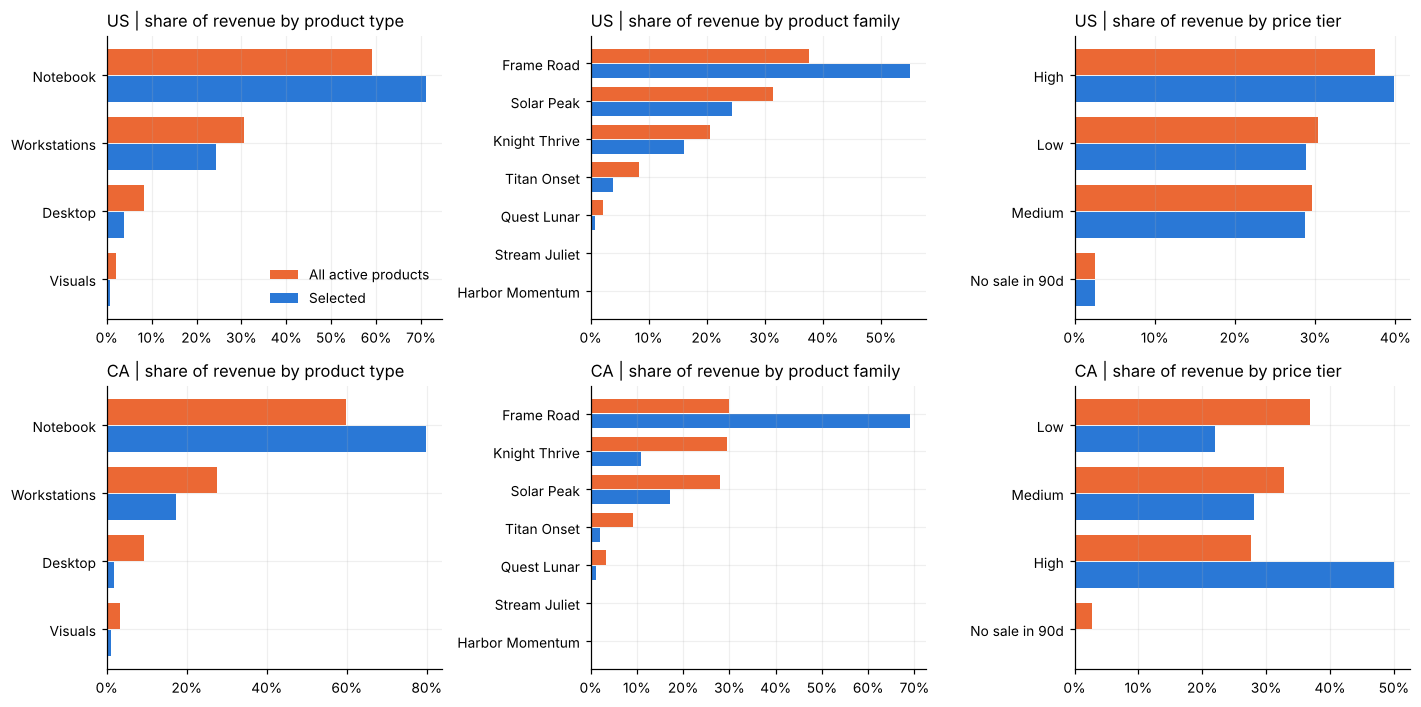

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for row, c in enumerate(["US", "CA"]):
    t = coverage_table(R[c]["stats"], R[c]["sel"])
    for ax, dim in zip(axes[row], ["product_type", "product_family", "price_tier"]):
        d = t[t.dimension == dim].copy()
        d["level"] = d.level.str.replace("Product Family ", "")
        d = d.sort_values("population_revenue_share")
        y = np.arange(len(d))
        ax.barh(y + .2, d.population_revenue_share, .38, color=POP_C, label="All active products")
        ax.barh(y - .2, d.selected_revenue_share, .38, color=SEL_C, label="Selected")
        ax.set_yticks(y, d.level); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax.set_title(f"{c} | share of revenue by {dim.replace('_', ' ')}", loc="left")
axes[0, 0].legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(OUT / "rule1_coverage.png", dpi=160); plt.show()

**Reading it:** both countries cover all 4 product types, all 4 major families and all three price tiers. The selection has no low-activity products, and only a handful of low-revenue ones. That is by design: the rule selects products with enough data to model. The mix is the thing to watch:
- **US** is close to the market. Frame Road carries more weight (55% of selected revenue vs 38% of the market), and Desktop and Visuals less.
- **Canada** is skewed. Frame Road is 69% of selected revenue vs 30% of the market. Knight Thrive is 30% of the market but only 3 selected products (11% of selected revenue), and Desktop/Titan Onset has 2 products.

## 3 | Rule 2 — Distributions vs the eligible population

For each feature: 25th percentile, median and 75th percentile of the selected products vs all active products; the relative difference in medians (flag if over 20%); and the Kolmogorov–Smirnov statistic (0 = identical distributions, 1 = no overlap).

Read the two feature groups differently:
- **Price features** should look like the population. The model learns price behaviour from the selection and applies it everywhere.
- **Size and activity features** are what the rule selects on, so the selection is expected to be larger and more active. A large difference there means the rule works; it is not a representativeness failure.

In [7]:
dist = {}
for c in ["US", "CA"]:
    s = R[c]["stats"]
    dist[c] = distribution_table(s, R[c]["sel"], pd.Series(True, index=s.index), MEDIAN_DIFF_FLAG)
    dist[c].to_csv(OUT / f"{c}_distribution_table.csv", index=False)
    display(Markdown(f"**{c}**"))
    display(dist[c].drop(columns="feature").style.format(
        {k: "{:,.3f}" for k in ["sel_p25", "sel_median", "sel_p75", "pop_p25", "pop_median", "pop_p75", "ks_stat"]}
        | {"median_diff": "{:+.0%}"}).hide(axis="index"))

**US**

label,group,sel_p25,sel_median,sel_p75,pop_p25,pop_median,pop_p75,median_diff,flag_gt_20pct,ks_stat
"ASP, last 90 days ($/unit)",price,"1,135.873","1,617.665","2,124.545","1,101.346","1,577.213","2,444.116",+3%,False,0.139
"ASP, last 6 months ($/unit)",price,"1,096.578","1,522.689","1,791.083","1,027.739","1,464.867","2,299.000",+4%,False,0.142
"Price dispersion (CV of transaction ASP, 6m)",price,0.128,0.154,0.190,0.101,0.139,0.186,+11%,False,0.208
"Price-outlier rate (1.5 IQR, 12m)",price,0.005,0.018,0.038,0.004,0.026,0.077,-33%,True,0.175
"Margin %, 6m",price,0.196,0.269,0.317,0.158,0.252,0.331,+7%,False,0.126
"Top-customer revenue share, 6m",price,0.512,0.555,0.604,0.517,0.574,0.648,-3%,False,0.180
"Revenue, last 90 days ($)",size/activity,"111,300.820","347,196.650","905,557.430","7,144.772","108,117.590","345,745.560",+221%,True,0.301
"Revenue, last 6 months ($)",size/activity,"557,207.600","1,385,707.100","2,736,748.820","57,886.550","246,692.850","720,712.890",+462%,True,0.451
"Units, last 6 months",size/activity,438.000,823.000,"1,775.000",36.000,204.000,528.000,+303%,True,0.472
"Transactions, last 6 months",size/activity,304.000,545.000,"1,237.000",32.000,137.000,358.000,+298%,True,0.514


**CA**

label,group,sel_p25,sel_median,sel_p75,pop_p25,pop_median,pop_p75,median_diff,flag_gt_20pct,ks_stat
"ASP, last 90 days ($/unit)",price,966.571,"1,665.208","1,918.535","1,040.355","1,432.050","2,298.805",+16%,False,0.175
"ASP, last 6 months ($/unit)",price,975.603,"1,578.739","1,789.547",950.475,"1,361.524","2,148.053",+16%,False,0.183
"Price dispersion (CV of transaction ASP, 6m)",price,0.138,0.161,0.189,0.095,0.138,0.190,+17%,False,0.287
"Price-outlier rate (1.5 IQR, 12m)",price,0.013,0.024,0.055,0.000,0.027,0.080,-14%,False,0.290
"Margin %, 6m",price,0.225,0.293,0.314,0.168,0.252,0.327,+16%,False,0.220
"Top-customer revenue share, 6m",price,0.493,0.527,0.594,0.533,0.607,0.740,-13%,False,0.367
"Revenue, last 90 days ($)",size/activity,"23,369.050","80,291.055","241,544.100","4,232.080","21,457.280","62,483.010",+274%,True,0.349
"Revenue, last 6 months ($)",size/activity,"120,925.685","363,742.385","554,561.230","16,856.228","52,016.995","123,236.622",+599%,True,0.567
"Units, last 6 months",size/activity,133.250,207.500,406.500,10.000,41.000,105.000,+406%,True,0.648
"Transactions, last 6 months",size/activity,101.750,147.000,275.250,9.000,31.500,68.000,+367%,True,0.673


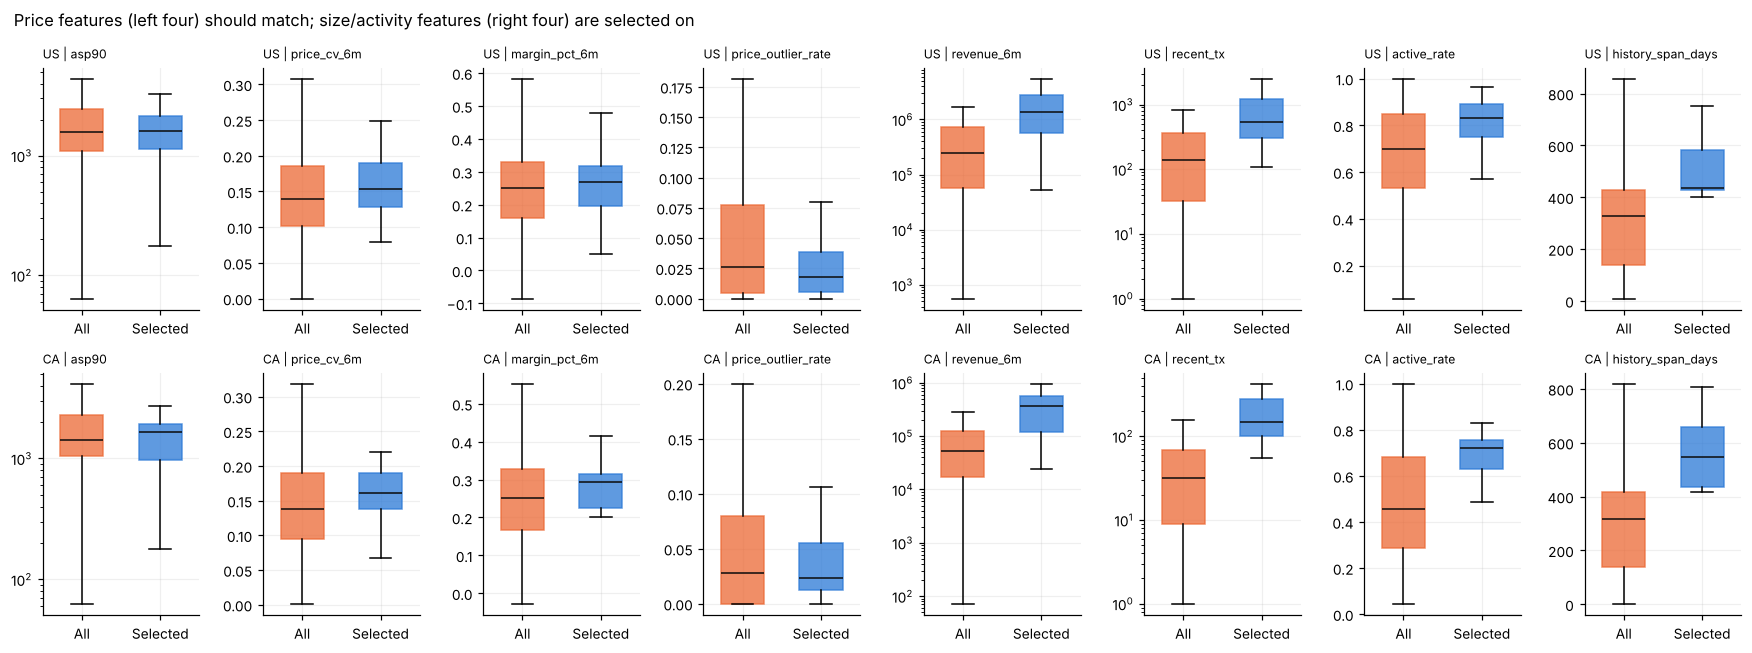

In [8]:
feats = ["asp90", "price_cv_6m", "margin_pct_6m", "price_outlier_rate", "revenue_6m", "recent_tx", "active_rate", "history_span_days"]
logf = {"asp90", "revenue_6m", "recent_tx"}
fig, axes = plt.subplots(2, len(feats), figsize=(16, 6))
for row, c in enumerate(["US", "CA"]):
    s = R[c]["stats"]
    for ax, f in zip(axes[row], feats):
        data = [s[f].dropna(), s.loc[R[c]["sel"], f].dropna()]
        bp = ax.boxplot(data, widths=.55, patch_artist=True, showfliers=False, medianprops=dict(color="#0b0b0b"))
        for b, col in zip(bp["boxes"], [POP_C, SEL_C]):
            b.set_facecolor(col); b.set_alpha(.75); b.set_edgecolor(col)
        ax.set_xticks([1, 2], ["All", "Selected"])
        if f in logf: ax.set_yscale("log")
        ax.set_title(f"{c} | {f}", fontsize=8, loc="left")
fig.suptitle("Price features (left four) should match; size/activity features (right four) are selected on", x=.01, ha="left")
fig.tight_layout(); fig.savefig(OUT / "rule2_distributions.png", dpi=160); plt.show()

Price compared **within product type**: a mix of more laptops can move the overall ASP even if each type is priced like the market.

In [9]:
for c in ["US", "CA"]:
    t = type_adjusted_price(R[c]["stats"], R[c]["sel"])
    t.to_csv(OUT / f"{c}_asp_by_type.csv", index=False)
    display(Markdown(f"**{c}** — `sel_percentile_of_median` = where the selected median sits in the population (0.5 = middle)"))
    display(t.style.format({"sel_median_asp90": "${:,.0f}", "pop_median_asp90": "${:,.0f}",
                            "median_diff": "{:+.0%}", "sel_percentile_of_median": "{:.2f}"}).hide(axis="index"))

**US** — `sel_percentile_of_median` = where the selected median sits in the population (0.5 = middle)

product_type,selected,sel_median_asp90,pop_median_asp90,median_diff,sel_percentile_of_median
Desktop,10,"$1,260","$1,377",-8%,0.39
Notebook,32,"$1,677","$1,469",+14%,0.62
Visuals,5,$300,$220,+36%,0.79
Workstations,14,"$2,464","$3,156",-22%,0.28


**CA** — `sel_percentile_of_median` = where the selected median sits in the population (0.5 = middle)

product_type,selected,sel_median_asp90,pop_median_asp90,median_diff,sel_percentile_of_median
Desktop,2,"$1,035","$1,277",-19%,0.23
Notebook,16,"$1,849","$1,387",+33%,0.74
Visuals,3,$202,$217,-7%,0.39
Workstations,3,"$1,796","$2,852",-37%,0.13


**Reading it:**
- **US:** five of the six price features are within 20% of the population (ASP +3%, margin +7%). The exception is the price-outlier rate: 1.8% vs 2.6% (−33%). Small absolute numbers, and expected, because products with more transactions have fewer extreme prices.
- **Canada:** all six price features are within 20%, but every one sits 13–17% from the population. Laptops in the selection are pricier (+33% vs the median Canadian laptop) and workstations cheaper (−37%).
- **Both countries:** within types, US workstations skew cheaper (−22%) and US monitors pricier (+36%, only 5 products with a recent ASP).
- **Size and activity:** as expected, the selected products are 3–6× larger and more active in both countries.

## 4 | Rule 3 — Stability under rule changes

**4a. Small changes, one at a time.** Each transaction gate moves about ±10–25%; each weekly-support setting moves ±1. `kept_from_base` = share of the current selection still selected; `jaccard` = overlap / union. Scenarios marked **[large]** change a rule's structure rather than nudge a threshold.

In [10]:
stab, freq_tables = {}, {}
for c in ["US", "CA"]:
    s, ws, base = R[c]["stats"], R[c]["ws"], R[c]["sel"]
    B = set(s.index[base]); rows, memb = [], {}
    for name, r in scenario_grid(c):
        _, m = select(s, ws, r); S = set(s.index[m]); memb[name] = m
        sc = coverage_scores(s, m)
        rows.append(dict(scenario=name, selected=len(S), kept_from_base=len(S & B) / len(B),
                         jaccard=len(S & B) / len(S | B), added=len(S - B), dropped=len(B - S),
                         types=sc["types_covered"], major_family_coverage=sc["major_family_coverage"],
                         price_tiers=len(sc["price_tiers"]), revenue_share=sc["revenue_share_6m"]))
    stab[c] = pd.DataFrame(rows)
    stab[c].to_csv(OUT / f"{c}_stability_scenarios.csv", index=False)
    small = [n for n in memb if n != "Base" and "[large]" not in n]
    f = pd.DataFrame(memb)[small].mean(axis=1)
    freq_tables[c] = s[KEYS].assign(selected_now=base, selection_frequency=f)
    display(Markdown(f"**{c}**"))
    display(stab[c].style.format({"kept_from_base": "{:.0%}", "jaccard": "{:.0%}",
                                  "major_family_coverage": "{:.0%}", "revenue_share": "{:.1%}"}).hide(axis="index"))

**US**

scenario,selected,kept_from_base,jaccard,added,dropped,types,major_family_coverage,price_tiers,revenue_share
Base,65,100%,100%,0,0,4/4,100%,3,35.4%
recent tx > 75,65,100%,100%,0,0,4/4,100%,3,35.4%
recent tx > 90,65,100%,100%,0,0,4/4,100%,3,35.4%
recent tx > 110,64,98%,98%,0,1,4/4,100%,3,35.4%
recent tx > 125,63,97%,97%,0,2,4/4,100%,3,35.2%
history tx > 75,72,100%,90%,7,0,4/4,100%,3,37.7%
history tx > 90,69,100%,94%,4,0,4/4,100%,3,36.9%
history tx > 110,62,95%,95%,0,3,4/4,100%,3,34.4%
history tx > 125,56,86%,86%,0,9,4/4,100%,3,31.4%
active months >= 2,66,100%,98%,1,0,4/4,100%,3,35.4%


**CA**

scenario,selected,kept_from_base,jaccard,added,dropped,types,major_family_coverage,price_tiers,revenue_share
Base,24,100%,100%,0,0,4/4,100%,3,19.1%
recent tx > 35,25,100%,96%,1,0,4/4,100%,3,19.2%
recent tx > 45,24,100%,100%,0,0,4/4,100%,3,19.1%
recent tx > 55,23,96%,96%,0,1,4/4,100%,3,19.0%
recent tx > 65,19,79%,79%,0,5,3/4,75%,3,18.3%
history tx > 35,32,100%,75%,8,0,4/4,100%,3,23.5%
history tx > 45,27,100%,89%,3,0,4/4,100%,3,21.1%
history tx > 55,21,88%,88%,0,3,4/4,100%,3,17.1%
history tx > 65,19,79%,79%,0,5,4/4,100%,3,15.7%
active months >= 2,25,100%,96%,1,0,4/4,100%,3,19.2%


**4b. Selection frequency** across the small-change scenarios (the doc's *selection stability*). Products selected now but kept in fewer than 75% of scenarios are the borderline ones.

In [11]:
for c in ["US", "CA"]:
    ft = freq_tables[c]
    cur = ft[ft.selected_now]
    print(f"{c}: {len(cur)} selected | median frequency {cur.selection_frequency.median():.0%} | "
          f"below 50%: {(cur.selection_frequency < .5).sum()} | below 75%: {(cur.selection_frequency < .75).sum()} | "
          f"not selected now but selected in >=50% of scenarios: {((~ft.selected_now) & (ft.selection_frequency >= .5)).sum()}")
    low = cur[cur.selection_frequency < .75].sort_values("selection_frequency")
    if len(low):
        display(low.style.format({"selection_frequency": "{:.0%}"}).hide(axis="index"))
    ft.to_csv(OUT / f"{c}_selection_frequency.csv", index=False)

US: 65 selected | median frequency 100% | below 50%: 0 | below 75%: 0 | not selected now but selected in >=50% of scenarios: 0
CA: 24 selected | median frequency 100% | below 50%: 0 | below 75%: 2 | not selected now but selected in >=50% of scenarios: 0


product_name,product_family,product_type,selected_now,selection_frequency
CLARITY ST A99V SKY 2 R0Z1400M 50X S X89,Product Family Titan Onset,Desktop,True,70%
QUANTUMCB 30 T4 WAY,Product Family Knight Thrive,Notebook,True,70%


**4c. How strict can we go?** Every gate tightens together: transaction minimums × k, active months +1 at k > 1 and +2 at k ≥ 2, weekly minimums × √k (US). The "2 of 3 earlier periods" rule stays at 2. Requiring all 3 periods means about two years of history, which almost no current product has: it drops the US to 9 products and Canada to 4 (scenario table above).

**US** — strictest setting that still covers all types, ≥80% of major families and all price tiers: **k = 3.0** (14 products)

k,recent_tx_gt,hist_tx_gt,active_months,usable_weeks,selected,types,major_family_coverage,price_tiers,revenue_share,kept_from_base,full_coverage
0.500000,50,50,3,9/7,87,4/4,100%,3,40.8%,100%,True
0.750000,75,75,3,9/7,75,4/4,100%,3,37.9%,100%,True
1.000000,100,100,3,9/7,65,4/4,100%,3,35.4%,100%,True
1.250000,125,125,4,10/8,47,4/4,100%,3,28.7%,72%,True
1.500000,150,150,4,11/9,39,4/4,100%,3,26.5%,60%,True
2.000000,200,200,5,13/10,28,4/4,100%,3,22.1%,43%,True
2.500000,250,250,5,14/11,22,4/4,100%,3,17.7%,34%,True
3.000000,300,300,6,16/12,14,4/4,100%,3,12.7%,22%,True
4.000000,400,400,6,18/14,8,4/4,75%,3,8.1%,12%,False
5.000000,500,500,6,20/16,4,2/4,50%,2,6.3%,6%,False


**CA** — strictest setting that still covers all types, ≥80% of major families and all price tiers: **k = 1.0** (24 products)

k,recent_tx_gt,hist_tx_gt,active_months,usable_weeks,selected,types,major_family_coverage,price_tiers,revenue_share,kept_from_base,full_coverage
0.500000,25,25,3,-,43,4/4,100%,3,28.3%,100%,True
0.750000,38,38,3,-,32,4/4,100%,3,23.3%,100%,True
1.000000,50,50,3,-,24,4/4,100%,3,19.1%,100%,True
1.250000,62,62,4,-,15,3/4,75%,3,15.0%,62%,False
1.500000,75,75,4,-,10,3/4,75%,3,8.8%,42%,False
2.000000,100,100,5,-,6,3/4,50%,2,5.1%,25%,False
2.500000,125,125,5,-,3,2/4,50%,2,3.7%,12%,False
3.000000,150,150,6,-,0,0/4,0%,0,0.0%,0%,False
4.000000,200,200,6,-,0,0/4,0%,0,0.0%,0%,False
5.000000,250,250,6,-,0,0/4,0%,0,0.0%,0%,False


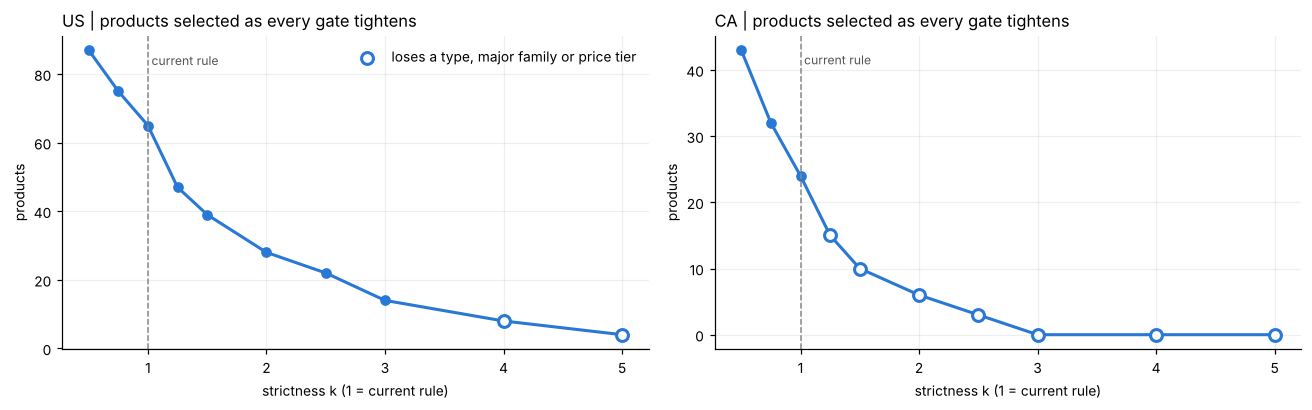

In [12]:
paths = {}
for c in ["US", "CA"]:
    s, ws, base = R[c]["stats"], R[c]["ws"], R[c]["sel"]
    rows = []
    for k, r in strictness_path(c):
        _, m = select(s, ws, r); sc = coverage_scores(s, m)
        rows.append(dict(k=k, recent_tx_gt=r.recent_tx, hist_tx_gt=r.hist_tx, active_months=r.recent_active_months,
                         usable_weeks=f"{r.min_recent_weeks}/{r.min_hist_weeks}" if r.weekly else "-",
                         selected=sc["selected"], types=sc["types_covered"], major_family_coverage=sc["major_family_coverage"],
                         price_tiers=len(sc["price_tiers"]), revenue_share=sc["revenue_share_6m"],
                         kept_from_base=len(set(s.index[m]) & set(s.index[base])) / base.sum(),
                         full_coverage=(sc["types_covered"] == "4/4") and sc["major_family_coverage"] >= .8 and len(sc["price_tiers"]) == 3))
    paths[c] = pd.DataFrame(rows)
    paths[c].to_csv(OUT / f"{c}_strictness_path.csv", index=False)
    ok = paths[c][paths[c].full_coverage]
    display(Markdown(f"**{c}** — strictest setting that still covers all types, ≥80% of major families and all price tiers: "
                     f"**k = {ok.k.max()}** ({int(ok.loc[ok.k.idxmax(), 'selected'])} products)"))
    display(paths[c].style.format({"major_family_coverage": "{:.0%}", "revenue_share": "{:.1%}", "kept_from_base": "{:.0%}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, c in zip(axes, ["US", "CA"]):
    p = paths[c]
    ax.plot(p.k, p.selected, color=SEL_C, lw=2, marker="o", ms=6)
    bad = p[~p.full_coverage]
    ax.scatter(bad.k, bad.selected, s=60, facecolor="white", edgecolor=SEL_C, zorder=3, linewidth=2,
               label="loses a type, major family or price tier")
    ax.axvline(1, color="#888", lw=1, ls="--"); ax.text(1.03, p.selected.max() * .95, "current rule", fontsize=8, color="#555")
    ax.set_title(f"{c} | products selected as every gate tightens", loc="left")
    ax.set_xlabel("strictness k (1 = current rule)"); ax.set_ylabel("products")
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "rule3_strictness.png", dpi=160); plt.show()

**Reading it:**
- **US is stable.** Every small change keeps at least 86% of the 65 products with full coverage, and no current product is selected in fewer than half the scenarios. Coverage survives up to about 3× stricter gates (14 products). If the model needs at least ~30 products, the US can go to about 1.5–2× (39 to 28 products).
- **Canada is at its edge.** Small changes keep 79–100% of the 24 products. But a slightly higher recent minimum (more than 65 transactions) already loses a product type, and so does 1.25× strictness. Two current products are kept in only 70% of scenarios. Applying the US-style weekly screen would cut Canada to 13 products and lose a type.

## 5 | Rule 4 — Model performance outside the selection

**Model.** This is a weekly price baseline matching the team's weekly support check. At each 7-day checkpoint it predicts the average selling price (ASP) over the next 7 days. It uses a convex blend of the product's ASP over the previous 7, 30, 90 and 180 days, with weights learned by minimising absolute % error. Naive ASP30 and ASP90 are benchmarks.

**Design.**
- **Train:** selected products, checkpoints whose 7-day target ends before Mar 2026.
- **Test:** every active product, checkpoints in Mar–Aug 2026.
- **Scored weeks:** only weeks where the product sold in both the prior 30 days and the next 7 days. Without a sale there is no ASP to predict.

**Caveat.** The selection itself used Mar–Aug 2026 activity, so this is a retrospective check of the selection. The model never sees test-period prices.

In [13]:
model_res, seg_res = {}, {}
for c in ["US", "CA"]:
    s, m, sel, cand = R[c]["stats"], R[c]["model"].copy(), R[c]["sel"], R[c]["cand"]
    m["group"] = np.where(m.pid.map(sel), "Selected",
                          np.where(m.pid.map(cand), "Passed tx gates, removed by weekly screen", "Not selected"))
    for col in ["product_type", "product_family", "price_tier", "activity_tier"]:
        m[col] = m.pid.map(s[col])
    tr = m[m.is_hist & (m.group == "Selected")]
    w = fit_relative_lad(tr[COMPONENTS].values, tr.target.values, tr.asp90.values)
    te = m[m.is_recent].copy()
    te["blend"] = te[COMPONENTS].values @ w
    R[c]["weights"], R[c]["test"] = dict(zip(COMPONENTS, w)), te
    print(f"{c}: trained on {len(tr):,} selected-product weeks | weights", {k: round(v, 3) for k, v in R[c]["weights"].items()})
    rows = []
    for g, d in te.groupby("group"):
        for name, col in [("Learned blend", "blend"), ("Naive ASP30", "asp30"), ("Naive ASP90", "asp90")]:
            rows.append(dict(group=g, model=name, products=d.pid.nunique(), **err_metrics(d.target.values, d[col].values)))
    model_res[c] = pd.DataFrame(rows)
    model_res[c].to_csv(OUT / f"{c}_model_by_group.csv", index=False)
    display(model_res[c].style.format({"MAPE": "{:.1%}", "median_APE": "{:.1%}", "price_WAPE": "{:.1%}",
                                       "bias": "{:+.1%}", "within_5pct": "{:.0%}"}).hide(axis="index"))
    te["ape"] = (te.blend - te.target).abs() / te.target
    pl = te.groupby(["group", "pid"]).ape.mean().groupby("group").describe()[["count", "25%", "50%", "75%"]]
    display(Markdown("Product-level MAPE (each product counts once)")); display(pl.style.format("{:.1%}", subset=["25%", "50%", "75%"]))

US: trained on 2,398 selected-product weeks | weights {'asp7': np.float64(0.529), 'asp30': np.float64(0.252), 'asp90': np.float64(0.219), 'asp180': np.float64(0.0)}


group,model,products,samples,MAPE,median_APE,price_WAPE,bias,within_5pct
Not selected,Learned blend,410,4529,8.7%,5.4%,9.9%,-2.7%,48%
Not selected,Naive ASP30,410,4529,9.2%,5.5%,10.5%,-2.4%,47%
Not selected,Naive ASP90,410,4529,11.2%,7.8%,13.1%,-7.0%,37%
"Passed tx gates, removed by weekly screen",Learned blend,11,134,7.2%,4.4%,8.1%,-2.3%,52%
"Passed tx gates, removed by weekly screen",Naive ASP30,11,134,8.3%,5.0%,9.3%,-2.1%,50%
"Passed tx gates, removed by weekly screen",Naive ASP90,11,134,9.6%,8.6%,10.7%,-4.4%,37%
Selected,Learned blend,65,1242,7.7%,5.5%,8.2%,-3.6%,46%
Selected,Naive ASP30,65,1242,8.3%,6.1%,8.9%,-3.9%,44%
Selected,Naive ASP90,65,1242,10.6%,8.3%,11.6%,-8.2%,33%


Product-level MAPE (each product counts once)

,count,25%,50%,75%
group,,,,
Not selected,410.000000,5.0%,7.4%,10.8%
"Passed tx gates, removed by weekly screen",11.000000,5.4%,6.9%,10.1%
Selected,65.000000,5.9%,7.3%,8.9%


CA: trained on 832 selected-product weeks | weights {'asp7': np.float64(0.25), 'asp30': np.float64(0.458), 'asp90': np.float64(0.063), 'asp180': np.float64(0.229)}


group,model,products,samples,MAPE,median_APE,price_WAPE,bias,within_5pct
Not selected,Learned blend,385,3451,10.7%,7.0%,10.8%,-3.3%,39%
Not selected,Naive ASP30,385,3451,11.2%,7.2%,11.1%,-1.8%,38%
Not selected,Naive ASP90,385,3451,11.6%,8.1%,12.1%,-4.9%,34%
Selected,Learned blend,24,415,8.9%,7.1%,9.2%,-3.7%,39%
Selected,Naive ASP30,24,415,9.4%,7.2%,9.7%,-2.3%,38%
Selected,Naive ASP90,24,415,10.2%,7.9%,10.7%,-5.8%,36%


Product-level MAPE (each product counts once)

,count,25%,50%,75%
group,,,,
Not selected,385.000000,6.1%,8.9%,12.9%
Selected,24.000000,7.1%,9.0%,10.9%


**By segment.** Ratio = segment MAPE ÷ MAPE on the selected products. A segment is flagged when its ratio exceeds the guide and it has at least 100 test weeks.

**US** — selected-product MAPE = 7.7%; flagged segments: 0

dimension,level,group,samples,MAPE,bias,ratio_to_selected,flag
product_type,Desktop,Not selected,1309,9.8%,-3.8%,1.27,False
product_type,Desktop,Selected,173,7.1%,-4.6%,0.93,False
product_type,Notebook,Not selected,1700,7.5%,-0.9%,0.97,False
product_type,Notebook,Selected,669,7.2%,-3.4%,0.94,False
product_type,Visuals,Not selected,637,6.5%,+1.3%,0.84,False
product_type,Visuals,Selected,105,8.9%,-1.7%,1.15,False
product_type,Workstations,Not selected,1017,10.4%,-3.6%,1.36,False
product_type,Workstations,Selected,295,8.6%,-3.7%,1.12,False
product_family,Frame Road,Not selected,681,7.3%,-0.5%,0.95,False
product_family,Frame Road,Selected,478,7.4%,-3.4%,0.96,False


**CA** — selected-product MAPE = 8.9%; flagged segments: 0

dimension,level,group,samples,MAPE,bias,ratio_to_selected,flag
product_type,Desktop,Not selected,697,11.5%,-5.9%,1.29,False
product_type,Desktop,Selected,26,5.9%,-1.2%,0.66,False
product_type,Notebook,Not selected,1415,9.5%,-1.7%,1.06,False
product_type,Notebook,Selected,285,9.1%,-4.2%,1.02,False
product_type,Visuals,Not selected,589,12.4%,-1.4%,1.39,False
product_type,Visuals,Selected,51,10.6%,+1.3%,1.18,False
product_type,Workstations,Not selected,750,10.9%,-4.0%,1.22,False
product_type,Workstations,Selected,53,8.1%,-2.6%,0.91,False
product_family,Frame Road,Not selected,615,10.5%,-1.3%,1.18,False
product_family,Frame Road,Selected,246,9.4%,-4.0%,1.05,False


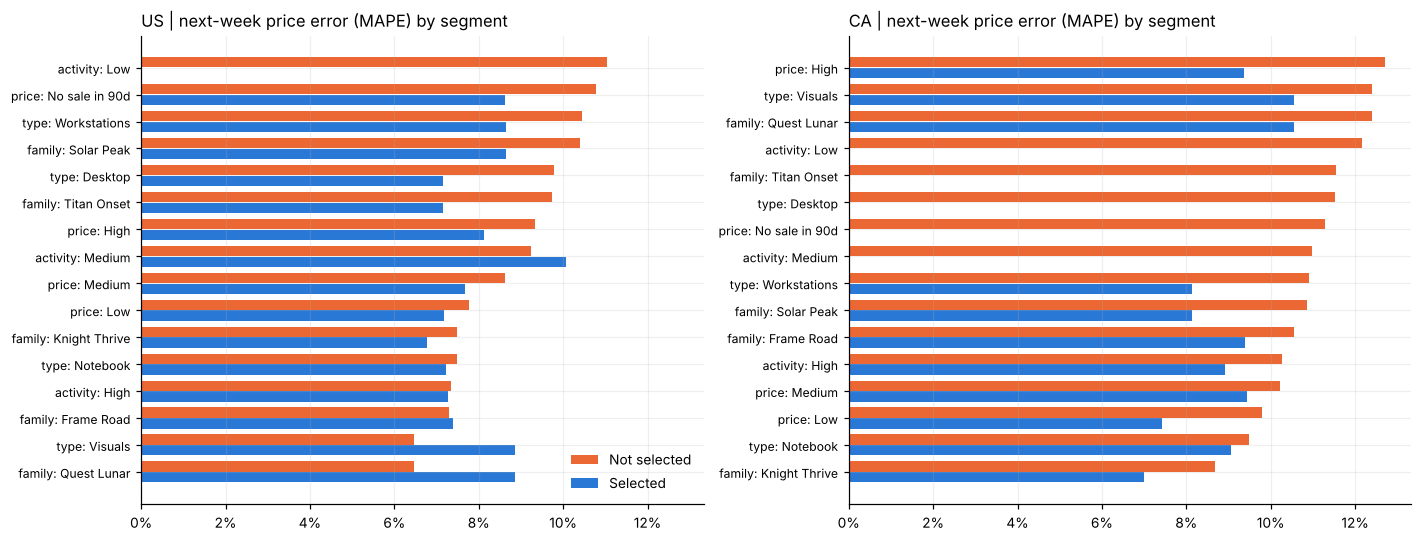

In [14]:
for c in ["US", "CA"]:
    te = R[c]["test"]
    ref = err_metrics(te[te.group == "Selected"].target.values, te[te.group == "Selected"].blend.values)["MAPE"]
    rows = []
    for col in ["product_type", "product_family", "price_tier", "activity_tier"]:
        for (lvl, g), d in te.groupby([col, te.group.where(te.group == "Selected", "Not selected")]):
            e = err_metrics(d.target.values, d.blend.values)
            rows.append(dict(dimension=col, level=str(lvl).replace("Product Family ", ""), group=g, samples=e["samples"],
                             MAPE=e["MAPE"], bias=e["bias"], ratio_to_selected=e["MAPE"] / ref,
                             flag=(e["MAPE"] / ref > MAX_SEGMENT_RATIO) and e["samples"] >= 100))
    seg_res[c] = pd.DataFrame(rows)
    seg_res[c].to_csv(OUT / f"{c}_model_by_segment.csv", index=False)
    display(Markdown(f"**{c}** — selected-product MAPE = {ref:.1%}; flagged segments: {int(seg_res[c].flag.sum())}"))
    display(seg_res[c].style.format({"MAPE": "{:.1%}", "bias": "{:+.1%}", "ratio_to_selected": "{:.2f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, c in zip(axes, ["US", "CA"]):
    t = seg_res[c][seg_res[c].samples >= 30].copy()
    t["label"] = t.dimension.str.replace("product_", "").str.replace("_tier", "") + ": " + t.level
    piv = t.pivot_table(index="label", columns="group", values="MAPE").sort_values("Not selected")
    y = np.arange(len(piv))
    ax.barh(y + .2, piv["Not selected"], .38, color=POP_C, label="Not selected")
    ax.barh(y - .2, piv["Selected"], .38, color=SEL_C, label="Selected")
    ax.set_yticks(y, piv.index, fontsize=8); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(f"{c} | next-week price error (MAPE) by segment", loc="left")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(OUT / "rule4_model_segments.png", dpi=160); plt.show()

**5b. Product-holdout cross-validation.** This is the doc's second generalisation test. All products with training and test weeks are split into 5 folds. The model trains on 4 folds and scores the held-out fold, until every product has been held out once.

**5c. Is the selection enough to train on?** Compare weights learned from the selected products with weights learned from **all** products, both scored on the products outside the selection. If the selection is representative for modelling, the two should score about the same.

In [15]:
hold, topall = {}, {}
for c in ["US", "CA"]:
    m, sel = R[c]["model"], R[c]["sel"]
    both = set(m[m.is_hist].pid) & set(m[m.is_recent].pid)
    ho = product_holdout(m, both)
    ho["group"] = np.where(ho.pid.map(sel), "Selected", "Not selected")
    hold[c] = pd.DataFrame([dict(group=g, products=d.pid.nunique(), **err_metrics(d.target.values, d.forecast.values))
                            for g, d in ho.groupby("group")])
    trA = m[m.is_hist]
    wA = fit_relative_lad(trA[COMPONENTS].values, trA.target.values, trA.asp90.values)
    te = R[c]["test"]; out = te[te.group != "Selected"]
    topall[c] = pd.DataFrame([
        dict(trained_on="Selected products only", **dict(zip(COMPONENTS, np.round(list(R[c]["weights"].values()), 3))),
             MAPE_outside=err_metrics(out.target.values, out.blend.values)["MAPE"]),
        dict(trained_on="All active products", **dict(zip(COMPONENTS, np.round(wA, 3))),
             MAPE_outside=err_metrics(out.target.values, out[COMPONENTS].values @ wA)["MAPE"])])
    display(Markdown(f"**{c} — product holdout (5 folds)**"))
    display(hold[c].style.format({"MAPE": "{:.1%}", "median_APE": "{:.1%}", "price_WAPE": "{:.1%}",
                                  "bias": "{:+.1%}", "within_5pct": "{:.0%}"}).hide(axis="index"))
    display(Markdown(f"**{c} — selected-trained vs all-trained weights, scored outside the selection**"))
    display(topall[c].style.format({"MAPE_outside": "{:.2%}"}).hide(axis="index"))

**US — product holdout (5 folds)**

group,products,samples,MAPE,median_APE,price_WAPE,bias,within_5pct
Not selected,272,3541,9.1%,5.9%,10.6%,-4.6%,44%
Selected,65,1242,7.9%,5.7%,8.5%,-4.5%,45%


**US — selected-trained vs all-trained weights, scored outside the selection**

trained_on,asp7,asp30,asp90,asp180,MAPE_outside
Selected products only,0.529000,0.252000,0.219000,0.000000,8.63%
All active products,0.433000,0.348000,0.096000,0.122000,8.71%


**CA — product holdout (5 folds)**

group,products,samples,MAPE,median_APE,price_WAPE,bias,within_5pct
Not selected,240,2465,11.4%,7.8%,11.8%,-5.7%,36%
Selected,24,415,9.1%,7.0%,9.5%,-4.4%,40%


**CA — selected-trained vs all-trained weights, scored outside the selection**

trained_on,asp7,asp30,asp90,asp180,MAPE_outside
Selected products only,0.250000,0.458000,0.063000,0.229000,10.71%
All active products,0.263000,0.419000,0.000000,0.319000,10.76%


**Reading it:**
- **US:** the selection-trained model scores 7.7% MAPE on selected products and 8.7% outside them (1.13×). The 11 products the weekly screen removed score 7.2%. Product-level medians are almost identical (7.3% vs 7.4%).
- **Canada:** 8.9% on selected products vs 10.7% outside (1.20×).
- **Segments:** no segment with at least 100 test weeks exceeds 1.5×. The weakest are low-activity products and US workstations (about 10–11%); in Canada, high-price products and monitors (about 12–13%).
- **Bias:** both countries under-predict prices by about 3% everywhere, a level shift the team should look at.
- **Selected vs all-product training:** the weights learned from the selection do as well outside it as weights learned from every product (US 8.6% vs 8.7%; CA 10.7% vs 10.8%). For this model, the selection loses nothing.

## 6 | Side-by-side: the exploratory "proposed" lists

`US_selected_product_newlist.csv` (62 groups) and `CA_selected_product_newlist.csv` (38 groups) were made to widen coverage, especially in Canada. They have no written rule, so stability (Rule 3) cannot be tested for them. Coverage, distributions and model performance can.

In [16]:
rows = []
for c in ["US", "CA"]:
    s, m = R[c]["stats"], R[c]["model"]
    lists = {"Current rule": R[c]["sel"]}
    if PROPOSED_LISTS[c].exists():
        lists["Proposed list"], _ = map_list(PROPOSED_LISTS[c], s)
    for name, mask in lists.items():
        sc = coverage_scores(s, mask)
        dt = distribution_table(s, mask, pd.Series(True, index=s.index)).set_index("feature")
        tr = m[m.is_hist & m.pid.map(mask)]
        w = fit_relative_lad(tr[COMPONENTS].values, tr.target.values, tr.asp90.values)
        te_in, te_out = m[m.is_recent & m.pid.map(mask)], m[m.is_recent & ~m.pid.map(mask)]
        fam = s[mask].groupby("product_family").revenue_6m.sum() / s[mask].revenue_6m.sum()
        rows.append(dict(country=c, selection=name, products=sc["selected"], revenue_share_6m=sc["revenue_share_6m"],
                         types=sc["types_covered"], major_family_coverage=sc["major_family_coverage"],
                         top_family_share_of_selected_revenue=fam.max(),
                         asp90_median_diff=dt.loc["asp90", "median_diff"], margin_median_diff=dt.loc["margin_pct_6m", "median_diff"],
                         MAPE_inside=err_metrics(te_in.target.values, te_in[COMPONENTS].values @ w)["MAPE"],
                         MAPE_outside=err_metrics(te_out.target.values, te_out[COMPONENTS].values @ w)["MAPE"]))
cmp = pd.DataFrame(rows)
cmp.to_csv(OUT / "current_vs_proposed.csv", index=False)
display(cmp.style.format({"revenue_share_6m": "{:.1%}", "major_family_coverage": "{:.0%}",
                          "top_family_share_of_selected_revenue": "{:.0%}", "asp90_median_diff": "{:+.0%}",
                          "margin_median_diff": "{:+.0%}", "MAPE_inside": "{:.1%}", "MAPE_outside": "{:.1%}"}).hide(axis="index"))

country,selection,products,revenue_share_6m,types,major_family_coverage,top_family_share_of_selected_revenue,asp90_median_diff,margin_median_diff,MAPE_inside,MAPE_outside
US,Current rule,65,35.4%,4/4,100%,55%,+3%,+7%,7.7%,8.6%
US,Proposed list,62,43.5%,4/4,100%,43%,+18%,-0%,7.6%,8.7%
CA,Current rule,24,19.1%,4/4,100%,69%,+16%,+16%,8.9%,10.7%
CA,Proposed list,38,34.5%,4/4,100%,41%,+6%,-2%,9.9%,10.9%


## 7 | Scorecard

In [17]:
rows = []
for c in ["US", "CA"]:
    sc = cov_summary.loc[c]
    r1 = sc["types_covered"].split("/")[0] == sc["types_covered"].split("/")[1] and sc["major_family_coverage"] >= .8 \
         and len(sc["price_tiers"]) == 3
    pf = dist[c][dist[c].group == "price"]
    n_ok = int((pf.median_diff.abs() <= MEDIAN_DIFF_FLAG).sum())
    small = stab[c][(stab[c].scenario != "Base") & ~stab[c].scenario.str.contains("large")]
    r3_ret = small.kept_from_base.min()
    r3_cov = (small.types.str[0] == "4").all() and (small.major_family_coverage >= .8).all()
    mr = model_res[c][model_res[c].model == "Learned blend"].set_index("group")
    ratio = mr.loc["Not selected", "MAPE"] / mr.loc["Selected", "MAPE"]
    flags = int(seg_res[c].flag.sum())
    beats = (model_res[c].pivot(index="group", columns="model", values="MAPE")["Learned blend"]
             <= model_res[c].pivot(index="group", columns="model", values="MAPE")["Naive ASP30"]).all()
    rows += [
        dict(country=c, rule="1 Coverage", result="PASS" if r1 else "FAIL",
             evidence=f"{sc['types_covered']} types, {sc['major_family_coverage']:.0%} of major families, price tiers {len(sc['price_tiers'])}/3; "
                      f"no low-activity products (by design); {sc['revenue_share_6m']:.0%} of recent revenue"),
        dict(country=c, rule="2 Distributions", result="PASS" if n_ok == len(pf) else ("PARTIAL" if n_ok >= len(pf) - 1 else "FAIL"),
             evidence=f"{n_ok}/{len(pf)} price features within {MEDIAN_DIFF_FLAG:.0%} of the population median; "
                      "size/activity higher by design"),
        dict(country=c, rule="3 Stability", result="PASS" if (r3_ret >= MIN_RETENTION and r3_cov) else "PARTIAL",
             evidence=f"worst small-change retention {r3_ret:.0%}; coverage kept in every small change: {r3_cov}; "
                      f"strictest full-coverage k = {paths[c][paths[c].full_coverage].k.max()}"),
        dict(country=c, rule="4 Performance outside", result="PASS" if (ratio <= MAX_OUTSIDE_RATIO and flags == 0 and beats) else "PARTIAL",
             evidence=f"MAPE {mr.loc['Selected', 'MAPE']:.1%} selected vs {mr.loc['Not selected', 'MAPE']:.1%} outside ({ratio:.2f}x); "
                      f"{flags} segments over {MAX_SEGMENT_RATIO}x; beats naive ASP30 in every group: {beats}"),
    ]
score = pd.DataFrame(rows)
score.to_csv(OUT / "scorecard.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(score.style.hide(axis="index"))

country,rule,result,evidence
US,1 Coverage,PASS,"4/4 types, 100% of major families, price tiers 3/3; no low-activity products (by design); 35% of recent revenue"
US,2 Distributions,PARTIAL,5/6 price features within 20% of the population median; size/activity higher by design
US,3 Stability,PASS,worst small-change retention 86%; coverage kept in every small change: True; strictest full-coverage k = 3.0
US,4 Performance outside,PASS,MAPE 7.7% selected vs 8.7% outside (1.13x); 0 segments over 1.5x; beats naive ASP30 in every group: True
CA,1 Coverage,PASS,"4/4 types, 100% of major families, price tiers 3/3; no low-activity products (by design); 19% of recent revenue"
CA,2 Distributions,PASS,6/6 price features within 20% of the population median; size/activity higher by design
CA,3 Stability,PARTIAL,worst small-change retention 79%; coverage kept in every small change: False; strictest full-coverage k = 1.0
CA,4 Performance outside,PASS,MAPE 8.9% selected vs 10.7% outside (1.20x); 0 segments over 1.5x; beats naive ASP30 in every group: True


**Bottom line**
- **US:** the selection meets all four rules. It is a defensible modelling population.
- **Canada:** coverage and model performance hold, but the selection is thin and sits at the edge of its rules:
  - One family carries 69% of selected revenue.
  - A slightly stricter rule loses a product type.
  - Two products are only borderline-stable.

  Canada needs one of two decisions before the baseline is retrained: (a) loosen the Canadian gates slightly (k = 0.75 gives 32 products with full coverage), or (b) add a few Knight Thrive and Desktop products by documented manual review. The proposed 38-product list does the latter: it covers 34% of recent revenue vs 19%, and no family exceeds 41% of selected revenue. Its error is similar outside the list (10.9% vs 10.7%) but higher on the list itself (9.9% vs 8.9%), because it adds newer, harder-to-predict products.

**Open items for the team:** confirm the acceptance guides in the Setup cell; decide whether the eligible population should stay "every active product" or something narrower; look into the consistent ~3% price under-prediction.